# Backpropagation
### ¿Cómo aprende una red neuronal de sus propios errores?

---

Una red neuronal aprende ajustando muchos números internos, llamados pesos, para que sus predicciones se parezcan cada vez más a las respuestas correctas. Backpropagation (propagación hacia atrás) es el método que indica cómo debe ajustarse cada peso: parte del error que comete la red en su salida y lo enmienda hacia atrás, capa por capa, hasta llegar a la entrada. Su herramienta matemática es la derivada, combinada mediante la regla de la cadena.

| # | Sección | Idea clave |
|---|---------|-----------|
| 1 | La idea en una frase | Una red es una máquina llena de perillas |
| 2 | La derivada | La derivada mide *sensibilidad* |
| 3 | Una neurona con un solo peso | Bajar por el "valle del error" |
| 4 | ¿Por qué no basta con probar? | El problema de los millones de perillas |
| 5 | La regla de la cadena | Engranajes que se multiplican |
| 6 | Backpropagation paso a paso | Enmendar el error hacia atrás |
| 7 | Funciones de activación | Una sección más en la cadena |
| 8 | De una neurona a una red | Lo mismo, pero con muchas neuronas |
| 9 | Proyecto: reconocer dígitos | Todo junto, en código |
| 10 | Resumen, glosario y ejercicios | Repaso y práctica |

In [1]:
# Librerías que usaremos en todo el tutorial
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

AZUL = "#2563eb"   # usaremos azul para el camino de IDA (forward)
ROJO = "#dc2626"   # y rojo para el camino de VUELTA (backward)
print("¡Listo! Todo cargado.")

¡Listo! Todo cargado.


---
## 1. La idea en una frase

Imaginemos que abrimos el grifo y el agua sale demasiado fría. ¿Qué haces?

1. Pruebas el agua → está fría.
2. Comparas con lo que querías → quería tibia, me faltan unos grados.
3. Decides hacia dónde girar la perilla y cuánto → "un poco hacia la izquierda".
4. Giras la perilla y vuelves a probar.

Ahora imaginemos una ducha con un millón de perillas, todas conectadas entre sí: mover una afecta lo que hacen las otras. Eso es una red neuronal: cada perilla es un número llamado peso.

Entrenar la red es repetir los 4 pasos de la ducha miles de veces:

| Ducha | Red neuronal | Nombre técnico |
|-------|--------------|----------------|
| Probar el agua | La red hace una predicción | *Forward pass* (paso hacia adelante) |
| Comparar con lo deseado | Medir qué tan mal predijo | *Función de pérdida* (error) |
| Decidir hacia dónde girar cada perilla | Calcular cuánto debe corregirse cada peso | Backpropagation |
| Girar las perillas | Ajustar los pesos un poquito | *Descenso del gradiente* |

Backpropagation es el método para responder, de forma rápida, la pregunta: *"si giro esta perilla un poquito, ¿el error sube o baja, y cuánto?"*, para todas las perillas a la vez.

Para responder esa pregunta necesitamos una sola herramienta matemática: la derivada. Vamos a verla.

---
## 2. La derivada

La derivada mide la sensibilidad: si muevo la entrada *un poquitico*, ¿cuánto se mueve la salida?

Ejemplo. Sea $f(w) = w^2$. Estamos en $w = 3$, así que $f(3) = 9$.

- Muevo $w$ un poquito: $w = 3.001$.
- Ahora $f(3.001) = 9.006001$.
- La salida se movió $0.006$ cuando la entrada se movió $0.001$. Es decir, se movió unas 6 veces más.

Ese "6" es la derivada de $f$ en $w=3$. Se escribe $\dfrac{df}{dw} = 6$. (Y en efecto, la regla dice que la derivada de $w^2$ es $2w$, y $2 \times 3 = 6$ ).

¿Qué nos dice el signo? Esto es lo más importante de todo el tutorial:

| Derivada | Significa | Si quiero que $f$ baje, debo... |
|----------|-----------|----------------------------------|
| positiva (+) | si $w$ sube, $f$ sube | bajar $w$ |
| negativa (−) | si $w$ sube, $f$ baja | subir $w$ |
| cero | estoy en un punto plano| quedarme quieto |

Para bajar el error, siempre hay que moverse en la dirección contraria a la derivada.

Las únicas tres reglas de derivación que usaremos (con $c$ un número fijo):

| Función | Derivada | En palabras |
|---------|----------|-------------|
| $c \cdot w$ | $c$ | multiplicar por $c$ amplifica los cambios $c$ veces |
| $w + c$ | $1$ | sumar una constante no cambia la sensibilidad |
| $w^2$ | $2w$ | la parábola es más empinada lejos del cero |

Comprobémoslo con código: vamos a calcular la derivada "empujando" la entrada un poquito, sin usar ninguna fórmula.

In [2]:
# La función que vamos a estudiar: f(w) = w²
def f(w):
    return w ** 2

# Calcula la derivada "empujando" w un poquito y midiendo cuánto cambia f
def derivada_numerica(funcion, w, h=0.001):
    valor_antes = funcion(w)         # valor de la función en w
    valor_despues = funcion(w + h)   # valor de la función después de empujar w un poquito
    cambio = valor_despues - valor_antes
    return cambio / h                # ¿cuántas veces más se movió la salida que la entrada?

# Comparamos el resultado de "empujar" con la fórmula 2w
for w in [-2, 0, 0.5, 3]:
    empujando = derivada_numerica(f, w)
    formula = 2 * w
    print("w =", w, "| empujando:", round(empujando, 4), "| fórmula 2w:", formula)

w = -2 | empujando: -3.999 | fórmula 2w: -4
w = 0 | empujando: 0.001 | fórmula 2w: 0
w = 0.5 | empujando: 1.001 | fórmula 2w: 1.0
w = 3 | empujando: 6.001 | fórmula 2w: 6


Coinciden. Ahora veámoslo en un dibujo: la derivada es la pendiente de la recta que "toca" la curva en ese punto.

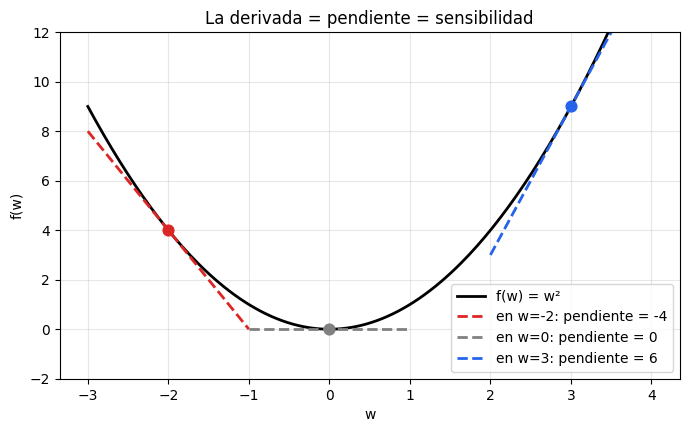

In [3]:
w = np.linspace(-3, 3.5, 200)
plt.figure(figsize=(8, 4.5))
plt.plot(w, f(w), color="black", lw=2, label="f(w) = w²")

for w0, color in [(-2, ROJO), (0, "gray"), (3, AZUL)]:
    pendiente = 2 * w0
    tramo = np.linspace(w0 - 1, w0 + 1, 10)
    plt.plot(tramo, f(w0) + pendiente * (tramo - w0), "--", color=color, lw=2,
             label=f"en w={w0}: pendiente = {pendiente}")
    plt.scatter([w0], [f(w0)], color=color, s=60, zorder=5)

plt.title("La derivada = pendiente = sensibilidad")
plt.xlabel("w"); plt.ylabel("f(w)"); plt.ylim(-2, 12); plt.legend()
plt.show()

- En $w=-2$ la pendiente es negativa (−4): si subo $w$, $f$ baja. Para llegar al mínimo, hay que subir $w$.
- En $w=3$ la pendiente es positiva (+6): si subo $w$, $f$ sube. Para llegar al mínimo, hay que bajar $w$.
- En $w=0$ la pendiente es cero: estamos en el fondo del valle.

---
## 3. Un modelo simple: una neurona con un solo peso

### El problema de las empanadas

Una tienda vende empanadas, pero nuestro modelo no sabe cuánto cuesta cada una. Solo tiene un dato de ejemplo:

- Se compraron 3 empanadas y se pagaron 6 mil pesos.

Nuestro "modelo" es una neurona con un solo peso $w$ (el precio que *cree* que tiene cada empanada):

$$\text{predicción} = w \cdot x \qquad (x = \text{número de empanadas})$$

Empezamos con una suposición cualquiera: $w = 0.5$. Entonces el modelo predice $0.5 \times 3 = 1.5$ mil pesos. ¡Muy lejos de 6 mil!

### ¿Cómo medimos "qué tan mal" lo hizo? La función de pérdida

Usamos el error al cuadrado:

$$L = (\text{predicción} - \text{real})^2$$

¿Por qué al cuadrado?
- Siempre da un número positivo (equivocarse por arriba o por abajo es igual de malo).
- Castiga más los errores grandes: equivocarse por 4 cuesta 16, equivocarse por 1 cuesta solo 1.
- Es fácil de derivar.

A $L$ le diremos pérdida, error o loss (son lo mismo).

In [4]:
x_empanadas = 3      # entrada: número de empanadas
y_real = 6           # lo que realmente se pagó (en miles de pesos)

def prediccion(w):
    return w * x_empanadas

def perdida(w):
    return (prediccion(w) - y_real) ** 2

w = 0.5
print(f"Con w = {w}: el modelo predice {prediccion(w)} mil pesos")
print(f"El precio real es {y_real} mil pesos")
print(f"Pérdida L = ({prediccion(w)} - {y_real})² = {perdida(w)}")

Con w = 0.5: el modelo predice 1.5 mil pesos
El precio real es 6 mil pesos
Pérdida L = (1.5 - 6)² = 20.25


In [5]:
prediccion(0.5)

1.5

### El valle del error

Para cada valor posible de $w$ hay un error distinto. Si dibujamos el error para muchos valores de $w$, obtenemos un valle. Entrenar el modelo = bajar al fondo del valle.

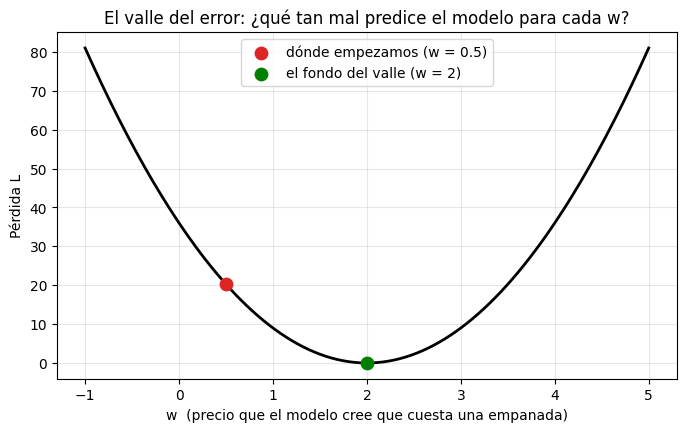

In [6]:
ws = np.linspace(-1, 5, 200)
plt.figure(figsize=(8, 4.5))
plt.plot(ws, perdida(ws), color="black", lw=2)
plt.scatter([0.5], [perdida(0.5)], color=ROJO, s=80, zorder=5, label="dónde empezamos (w = 0.5)")
plt.scatter([2], [0], color="green", s=80, zorder=5, label="el fondo del valle (w = 2)")
plt.title("El valle del error: ¿qué tan mal predice el modelo para cada w?")
plt.xlabel("w  (precio que el modelo cree que cuesta una empanada)")
plt.ylabel("Pérdida L")
plt.legend(); plt.show()

Nosotros sabemos que el fondo está en $w=2$ (cada empanada cuesta 2 mil). Pero la red no puede ver el dibujo: solo puede "tantear" dónde está parada, como alguien bajando una montaña con niebla: solo siente la inclinación del suelo bajo sus pies.

### Descenso del gradiente: la regla para bajar

En cada paso:

$$\boxed{w_{\text{nuevo}} = w_{\text{actual}} - \eta \cdot \frac{dL}{dw}}$$

- $\dfrac{dL}{dw}$ es la pendiente (derivada) del error en el punto donde estamos. A la derivada de la pérdida la llamamos gradiente.
- El signo menos hace que nos movamos en la dirección contraria a la pendiente.
- $\eta$ (la letra griega "eta") es la tasa de aprendizaje: el tamaño del paso. Un número pequeño, como 0.02.

Por ahora calcularemos la pendiente "empujando" a $w$, con la función `derivada_numerica` de la Sección 2.

In [7]:
w = 0.5
eta = 0.02                     # tasa de aprendizaje (tamaño del paso)
historia = [w]

print("paso |   w    | predicción | pérdida | pendiente dL/dw")
print("-----+--------+------------+---------+----------------")
for paso in range(10):
    pendiente = derivada_numerica(perdida, w)
    print(f"{paso:4} | {w:6.3f} | {prediccion(w):10.3f} | {perdida(w):7.3f} | {pendiente:10.3f}")
    w = w - eta * pendiente #Descenso de gradiente
    historia.append(w)

print(f"\nDespués de 10 pasos: w = {w:.3f}  (el valor ideal es 2)")

paso |   w    | predicción | pérdida | pendiente dL/dw
-----+--------+------------+---------+----------------
   0 |  0.500 |      1.500 |  20.250 |    -26.991
   1 |  1.040 |      3.119 |   8.298 |    -17.274
   2 |  1.385 |      4.156 |   3.401 |    -11.056
   3 |  1.606 |      4.819 |   1.394 |     -7.076
   4 |  1.748 |      5.244 |   0.572 |     -4.528
   5 |  1.838 |      5.515 |   0.235 |     -2.898
   6 |  1.896 |      5.689 |   0.096 |     -1.855
   7 |  1.934 |      5.801 |   0.040 |     -1.187
   8 |  1.957 |      5.872 |   0.016 |     -0.760
   9 |  1.972 |      5.917 |   0.007 |     -0.486

Después de 10 pasos: w = 1.982  (el valor ideal es 2)


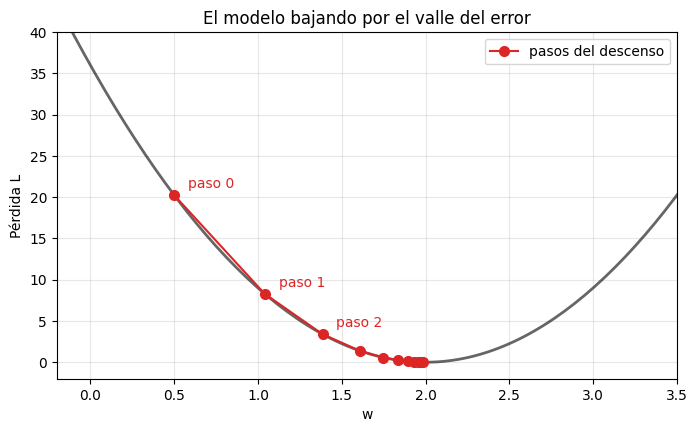

In [8]:
historia = np.array(historia)
plt.figure(figsize=(8, 4.5))
plt.plot(ws, perdida(ws), color="black", lw=2, alpha=0.6)
plt.plot(historia, perdida(historia), "o-", color=ROJO, ms=7, label="pasos del descenso")
for i in [0, 1, 2]:
    plt.annotate(f"paso {i}", (historia[i], perdida(historia[i])), textcoords="offset points",
                 xytext=(10, 5), color=ROJO)
plt.title("El modelo bajando por el valle del error")
plt.xlabel("w"); plt.ylabel("Pérdida L"); plt.xlim(-0.2, 3.5); plt.ylim(-2, 40); plt.legend()
plt.show()

Fijémonos en dos cosas:
1. Al principio la pendiente es muy negativa → el modelo da pasos grandes hacia la derecha.
2. Cerca del fondo la pendiente es casi cero → los pasos se hacen pequeñitos. ¡El método frena solito!

### Experimento: ¿qué pasa si cambio el tamaño del paso $\eta$?

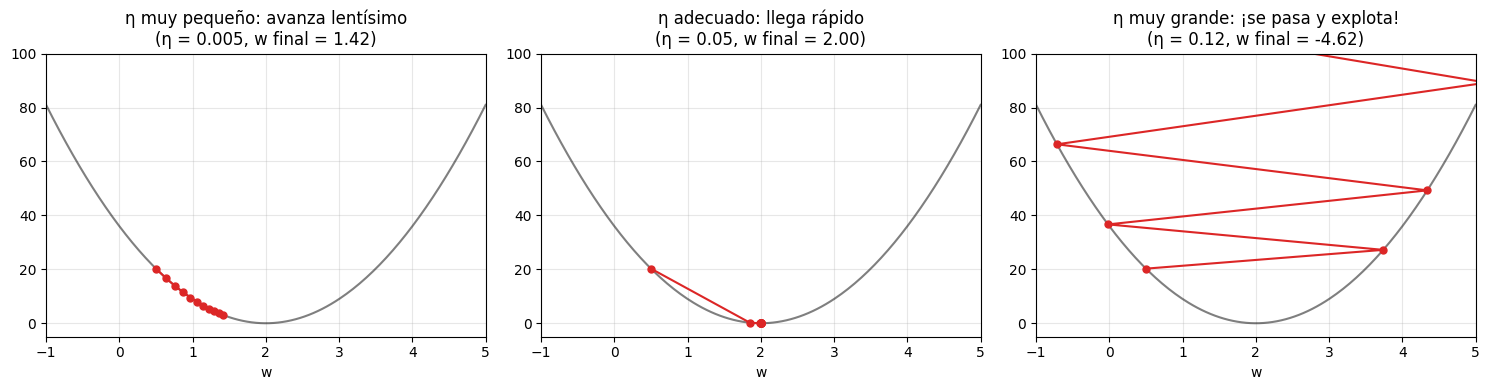

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, eta_prueba, titulo in zip(axes, [0.005, 0.05, 0.12],
                                  ["η muy pequeño: avanza lentísimo",
                                   "η adecuado: llega rápido",
                                   "η muy grande: ¡se pasa y explota!"]):
    w = 0.5
    camino = [w]
    for _ in range(10):
        w = w - eta_prueba * derivada_numerica(perdida, w)
        camino.append(w)
    camino = np.array(camino)
    ax.plot(ws, perdida(ws), color="black", alpha=0.5)
    ax.plot(camino, perdida(camino), "o-", color=ROJO, ms=5)
    ax.set_title(f"{titulo}\n(η = {eta_prueba}, w final = {camino[-1]:.2f})")
    ax.set_xlim(-1, 5); ax.set_ylim(-5, 100); ax.set_xlabel("w")
plt.tight_layout(); plt.show()

La tasa de aprendizaje es como la sensibilidad de la perilla de la ducha: muy poca y tardas una eternidad en llegar a la temperatura; demasiada y pasas de helado a hirviendo una y otra vez.

---
## 4. ¿Por qué no basta con "empujar" cada peso?

En la Sección 3 calculamos la pendiente empujando el peso un poquito y midiendo el cambio. Funciona perfecto... con un peso.

Pero las redes reales tienen muchísimos pesos:

| Red | Número aproximado de pesos |
|-----|---------------------------|
| La que haremos en la Sección 9 | ~2 400 |
| Una red típica para imágenes médicas | ~25 millones |
| Un modelo de lenguaje grande | cientos de miles de millones |

Para "empujar" cada peso hay que volver a ejecutar toda la red una vez por cada peso. Con 25 millones de pesos, ¡serían 25 millones de ejecuciones para dar un solo paso!

Backpropagation calcula todas las derivadas con apenas una ejecución hacia adelante + una ejecución hacia atrás. Esa es la razón por la que el aprendizaje profundo es posible.

El truco que lo hace posible se llama regla de la cadena.

---
## 5. La regla de la cadena: engranajes

Imagina tres engranajes conectados: A → B → C.
- Cuando A da 1 vuelta, B da 2 vueltas.
- Cuando B da 1 vuelta, C da 3 vueltas.

Pregunta: cuando A da 1 vuelta, ¿cuántas da C?

Respuesta: $2 \times 3 = 6$ vueltas. Las sensibilidades se multiplican.

Eso es *exactamente* la regla de la cadena:

$$\boxed{\frac{dC}{dA} = \frac{dC}{dB} \cdot \frac{dB}{dA}}$$

Regla de la cadena en palabras: para saber cuánto afecta el primer eslabón al último, multiplica cuánto afecta cada eslabón al siguiente.

Comprobémoslo:

In [10]:
# Engranaje B: se mueve 2 veces lo que se mueve A
def B_de_A(a):
    return 2 * a

# Engranaje C: se mueve 3 veces lo que se mueve B
def C_de_B(b):
    return 3 * b

# La cadena completa: primero A mueve a B, luego B mueve a C
def C_de_A(a):
    b = B_de_A(a)
    c = C_de_B(b)
    return c

# Forma 1: empujar A un poquito y medir cuánto se mueve C
empujando = derivada_numerica(C_de_A, 1)

# Forma 2: multiplicar las sensibilidades de cada engranaje (regla de la cadena)
dB_dA = 2
dC_dB = 3
regla_cadena = dC_dB * dB_dA

print("dC/dA empujando A:", round(empujando, 4))
print("dC/dB · dB/dA (regla de la cadena):", dC_dB, "·", dB_dA, "=", regla_cadena)

dC/dA empujando A: 6.0
dC/dB · dB/dA (regla de la cadena): 3 · 2 = 6


### Volvamos a las empanadas

La pérdida de las empanadas también es una cadena de dos eslabones:

$$w \;\xrightarrow{\;\times 3\;}\; \text{pred} \;\xrightarrow{\;-6\;}\; u \;\xrightarrow{\;(\;)^2\;}\; L$$

Juntemos los dos primeros: $u = 3w - 6$ (cuánto se equivoca) y $L = u^2$.

| Eslabón | Sensibilidad local | Regla usada |
|---------|-------------------|-------------|
| $u = 3w - 6$ | $\dfrac{du}{dw} = 3$ | $c\cdot w$ y $w + c$ |
| $L = u^2$ | $\dfrac{dL}{du} = 2u$ | $w^2$ |

Por la regla de la cadena: $\dfrac{dL}{dw} = \dfrac{dL}{du}\cdot\dfrac{du}{dw} = 2u \cdot 3$.

En $w = 0.5$: $u = 3(0.5) - 6 = -4.5$, entonces $\dfrac{dL}{dw} = 2(-4.5)(3) = -27$.

¡Ya no necesitamos "empujar"! Basta con multiplicar derivadas sencillitas.

In [11]:
w = 0.5
u = 3 * w - 6
gradiente_cadena = (2 * u) * 3
print(f"Regla de la cadena: dL/dw = 2·({u})·3 = {gradiente_cadena}")
print(f"Empujando el peso:  dL/dw ≈ {derivada_numerica(perdida, w):.3f}")

Regla de la cadena: dL/dw = 2·(-4.5)·3 = -27.0
Empujando el peso:  dL/dw ≈ -26.991


---
## 6. Backpropagation paso a paso (el ejemplo central)

Haremos una "red" con dos pesos encadenados. Todos los números son pequeños, de modo que el cálculo puede seguirse con lápiz y papel.

### La red

$$x \;\xrightarrow{\;\times w_1\;}\; h \;\xrightarrow{\;\times w_2\;}\; y \;\xrightarrow{\;(y - y_{\text{real}})^2\;}\; L$$

| Símbolo | Qué es | Valor inicial |
|---------|--------|---------------|
| $x$ | la entrada | $1$ |
| $w_1$ | peso de la capa 1 | $2$ |
| $h$ | resultado intermedio ("neurona oculta") | se calcula |
| $w_2$ | peso de la capa 2 | $1$ |
| $y$ | la predicción de la red | se calcula |
| $y_{\text{real}}$ | la respuesta correcta | $4$ |
| $L$ | la pérdida | se calcula |

El objetivo: descubrir cómo ajustar $w_1$ y $w_2$ para que la red prediga 4.

Analogía: una fábrica con dos estaciones. La estación 1 (con su perilla $w_1$) procesa la materia prima $x$ y produce una pieza intermedia $h$. La estación 2 (con su perilla $w_2$) toma $h$ y produce el producto final $y$. El inspector de calidad al final compara $y$ con lo pedido y anota el error $L$. Cuando hay un error, se enmienda hacia atrás: primero se determina cómo debería cambiar el producto final, luego qué debe ajustar la estación 2 y, con esa información, qué debe ajustar la estación 1. Eso es backpropagation.

Función auxiliar para dibujar la red:

In [12]:
def dibujar_cadena(nombres, operaciones, valores, gradientes=None, grad_ops=None, titulo=""):
    n = len(nombres)
    sep = 3.0
    fig, ax = plt.subplots(figsize=(2.9 * n, 3.4))
    for i, (nom, val) in enumerate(zip(nombres, valores)):
        cx = i * sep
        ax.add_patch(plt.Circle((cx, 0), 0.62, facecolor="#dbeafe", edgecolor=AZUL, lw=2))
        ax.text(cx, 0.17, nom, ha="center", va="center", fontsize=15)
        ax.text(cx, -0.22, f"{val:.4g}", ha="center", va="center", fontsize=12, color=AZUL)
        if gradientes is not None and gradientes[i] is not None:
            ax.text(cx, -1.0, f"∂L/∂{nom}\n= {gradientes[i]:.4g}", ha="center", va="top",
                    fontsize=11, color=ROJO)
    for i, op in enumerate(operaciones):
        x0, x1 = i * sep + 0.65, (i + 1) * sep - 0.65
        ax.annotate("", xy=(x1, 0.2), xytext=(x0, 0.2),
                    arrowprops=dict(arrowstyle="->", color=AZUL, lw=2))
        ax.text((x0 + x1) / 2, 0.42, op, ha="center", va="bottom", fontsize=11, color=AZUL)
        if gradientes is not None:
            ax.annotate("", xy=(x0, -0.35), xytext=(x1, -0.35),
                        arrowprops=dict(arrowstyle="->", color=ROJO, lw=2, ls="--"))
            if grad_ops is not None and grad_ops[i] is not None:
                ax.text((x0 + x1) / 2, -0.62, grad_ops[i], ha="center", va="top",
                        fontsize=10, color=ROJO,
                        bbox=dict(boxstyle="round", fc="#fee2e2", ec=ROJO))
    ax.set_xlim(-1, (n - 1) * sep + 1); ax.set_ylim(-2.1, 1.3)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(titulo, fontsize=13)
    plt.show()

### Paso 1 → Forward pass (ida): la red hace su predicción

Simplemente seguimos las flechas de izquierda a derecha:

$$h = w_1 \cdot x = 2 \cdot 1 = 2$$
$$y = w_2 \cdot h = 1 \cdot 2 = 2$$
$$L = (y - y_{\text{real}})^2 = (2 - 4)^2 = 4$$

La red predijo 2, pero la respuesta era 4. Error: $L = 4$.

h = w1·x = 2.0·1.0 = 2.0
y = w2·h = 1.0·2.0 = 2.0
L = (y - y_real)² = (2.0 - 4.0)² = 4.0


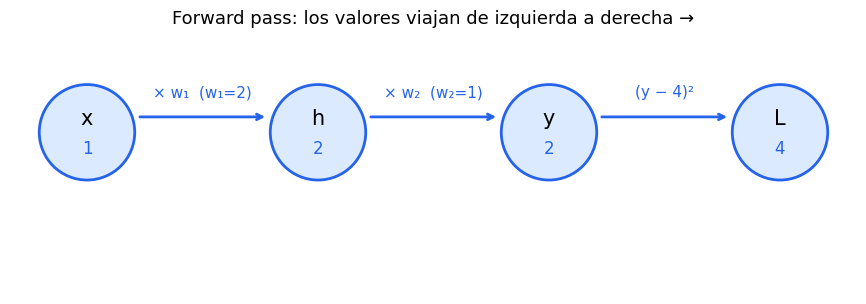

In [13]:
# Valores iniciales
x, w1, w2, y_real = 1.0, 2.0, 1.0, 4.0

# ---- FORWARD PASS (ida) ----
h = w1 * x
y = w2 * h
L = (y - y_real) ** 2

print(f"h = w1·x = {w1}·{x} = {h}")
print(f"y = w2·h = {w2}·{h} = {y}")
print(f"L = (y - y_real)² = ({y} - {y_real})² = {L}")

dibujar_cadena(["x", "h", "y", "L"],
               [f"× w₁  (w₁={w1:g})", f"× w₂  (w₂={w2:g})", f"(y − {y_real:g})²"],
               [x, h, y, L],
               titulo="Forward pass: los valores viajan de izquierda a derecha →")

### Paso 2 → Backward pass (vuelta): enmendar el error hacia atrás ←

Queremos saber $\dfrac{\partial L}{\partial w_1}$ y $\dfrac{\partial L}{\partial w_2}$: cuánto cambia el error si muevo cada perilla.

> Usamos el símbolo $\partial$ ("de parcial") en vez de $d$ porque ahora hay varias perillas. Significa lo mismo: *"cuánto cambia L si muevo solo esta cosa, dejando todo lo demás quieto"*.

La idea clave: cada sección de la red solo necesita conocer su derivada local, una derivada facilísima:

| Sección | Fórmula | Derivadas locales |
|------|---------|-------------------|
| Inspector | $L = (y - y_{\text{real}})^2$ | $\dfrac{\partial L}{\partial y} = 2(y - y_{\text{real}})$ |
| Estación 2 | $y = w_2 \cdot h$ | $\dfrac{\partial y}{\partial w_2} = h \qquad \dfrac{\partial y}{\partial h} = w_2$ |
| Estación 1 | $h = w_1 \cdot x$ | $\dfrac{\partial h}{\partial w_1} = x$ |

Ahora vamos de derecha a izquierda, multiplicando (regla de la cadena):

---

(A) ¿Cómo debería cambiar la salida $y$?

$$\frac{\partial L}{\partial y} = 2(y - y_{\text{real}}) = 2(2 - 4) = -4$$

*Significa:* si $y$ sube un poquito, el error baja 4 veces eso. → Queremos que $y$ suba. (Tiene sentido: predijo 2 y debía ser 4.)

---

(B) ¿Cómo debe corregirse la perilla $w_2$?

$$\frac{\partial L}{\partial w_2} = \underbrace{\frac{\partial L}{\partial y}}_{-4} \cdot \underbrace{\frac{\partial y}{\partial w_2}}_{h \,=\, 2} = -4 \cdot 2 = -8$$

---

(C) ¿Qué corrección le transmite la estación 2 a la estación 1 (a través de $h$)?

$$\frac{\partial L}{\partial h} = \underbrace{\frac{\partial L}{\partial y}}_{-4} \cdot \underbrace{\frac{\partial y}{\partial h}}_{w_2 \,=\, 1} = -4 \cdot 1 = -4$$

---

(D) ¿Cómo debe corregirse la perilla $w_1$?

$$\frac{\partial L}{\partial w_1} = \underbrace{\frac{\partial L}{\partial h}}_{-4} \cdot \underbrace{\frac{\partial h}{\partial w_1}}_{x \,=\, 1} = -4 \cdot 1 = -4$$

---

En (B) y (C) reutilizamos el $-4$ que calculamos en (A). Y en (D) reutilizamos el $-4$ de (C). Nunca repetimos trabajo: cada sección recibe la corrección que viene "de atrás", la multiplica por su derivada local y la transmite a la sección anterior. Por eso se llama back-propagation: *propagación hacia atrás*.

(A)  ∂L/∂y  = 2·(2.0 − 4.0)   = -4.0
(B)  ∂L/∂w2 = ∂L/∂y · h  = -4.0·2.0 = -8.0
(C)  ∂L/∂h  = ∂L/∂y · w2 = -4.0·1.0 = -4.0
(D)  ∂L/∂w1 = ∂L/∂h · x  = -4.0·1.0 = -4.0


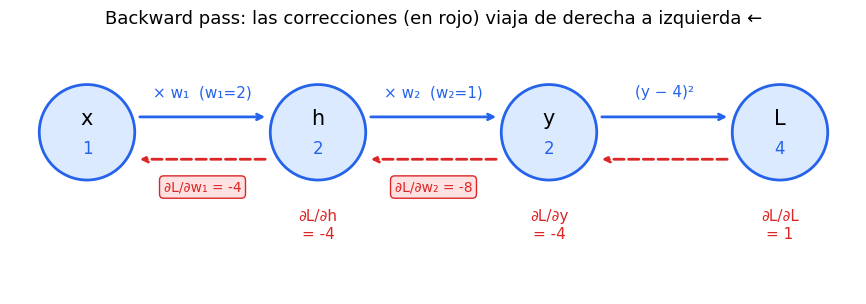

In [14]:
# ---- BACKWARD PASS (vuelta) ----
# Cada línea = "corrección que llega" × "derivada local"
dL_dy  = 2 * (y - y_real)     # (A)  inspector
dL_dw2 = dL_dy * h            # (B)  perilla w2      (derivada local: ∂y/∂w2 = h)
dL_dh  = dL_dy * w2           # (C)  corrección que pasa a h (derivada local: ∂y/∂h = w2)
dL_dw1 = dL_dh * x            # (D)  perilla w1      (derivada local: ∂h/∂w1 = x)

print(f"(A)  ∂L/∂y  = 2·({y} − {y_real})   = {dL_dy}")
print(f"(B)  ∂L/∂w2 = ∂L/∂y · h  = {dL_dy}·{h} = {dL_dw2}")
print(f"(C)  ∂L/∂h  = ∂L/∂y · w2 = {dL_dy}·{w2} = {dL_dh}")
print(f"(D)  ∂L/∂w1 = ∂L/∂h · x  = {dL_dh}·{x} = {dL_dw1}")

dibujar_cadena(["x", "h", "y", "L"],
               [f"× w₁  (w₁={w1:g})", f"× w₂  (w₂={w2:g})", f"(y − {y_real:g})²"],
               [x, h, y, L],
               gradientes=[None, dL_dh, dL_dy, 1.0],
               grad_ops=[f"∂L/∂w₁ = {dL_dw1:g}", f"∂L/∂w₂ = {dL_dw2:g}", None],
               titulo="Backward pass: las correcciones (en rojo) viaja de derecha a izquierda ←")

### ¿Y cómo sé que está bien? Comprobación "empujando"

Hagamos lo mismo de la Sección 2: empujar cada perilla un poquito y ver cuánto cambia el error. Si backpropagation está bien, deberíamos obtener los mismos números.

In [15]:
def red_completa(w1, w2):
    """Ejecuta toda la red y devuelve la pérdida."""
    return (w2 * (w1 * x) - y_real) ** 2

empuje_w1 = derivada_numerica(lambda a: red_completa(a, w2), w1)
empuje_w2 = derivada_numerica(lambda b: red_completa(w1, b), w2)

print(f"∂L/∂w1 → backprop: {dL_dw1:6.3f} | empujando: {empuje_w1:6.3f}")
print(f"∂L/∂w2 → backprop: {dL_dw2:6.3f} | empujando: {empuje_w2:6.3f}")

∂L/∂w1 → backprop: -4.000 | empujando: -3.999
∂L/∂w2 → backprop: -8.000 | empujando: -7.996


¡Coinciden! La diferencia: para "empujar" tuvimos que ejecutar la red completa una vez por cada peso. Backpropagation obtuvo los dos gradientes con una sola pasada hacia atrás.

### Paso 3 → Actualizar los pesos (descenso del gradiente)

Ambos gradientes son negativos → hay que subir ambas perillas. Con $\eta = 0.1$:

$$w_1 \leftarrow 2 - 0.1 \cdot (-4) = 2.4$$
$$w_2 \leftarrow 1 - 0.1 \cdot (-8) = 1.8$$

Fíjate que $w_2$ se mueve el doble que $w_1$: su corrección era el doble de grande.

In [16]:
eta = 0.1
w1_nuevo = w1 - eta * dL_dw1
w2_nuevo = w2 - eta * dL_dw2
print(f"w1: {w1} → {w1_nuevo}")
print(f"w2: {w2} → {w2_nuevo}")

# ¿Mejoró? Volvemos a hacer el forward pass con los pesos nuevos
y_nuevo = w2_nuevo * (w1_nuevo * x)
L_nuevo = (y_nuevo - y_real) ** 2
print(f"\nAntes:   predicción = {y:.3f}, pérdida = {L:.4f}")
print(f"Después: predicción = {y_nuevo:.3f}, pérdida = {L_nuevo:.4f}")
print(f"\nEl error bajó de {L} a {L_nuevo:.4f} en un solo paso")

w1: 2.0 → 2.4
w2: 1.0 → 1.8

Antes:   predicción = 2.000, pérdida = 4.0000
Después: predicción = 4.320, pérdida = 0.1024

El error bajó de 4.0 a 0.1024 en un solo paso


### Paso 4 → Repetir, repetir, repetir

Entrenar una red es simplemente repetir el ciclo ida → error → vuelta → ajuste muchas veces.

In [17]:
w1, w2 = 2.0, 1.0       # volvemos a los valores iniciales
eta = 0.1
registro = []

print("iter |   w1    |   w2    | predicción |  pérdida")
print("-----+---------+---------+------------+----------")
for it in range(15):
    # 1. Forward
    h = w1 * x
    y = w2 * h
    L = (y - y_real) ** 2
    # 2. Backward
    dL_dy  = 2 * (y - y_real)
    dL_dw2 = dL_dy * h
    dL_dh  = dL_dy * w2
    dL_dw1 = dL_dh * x
    # 3. Actualizar
    w1 -= eta * dL_dw1
    w2 -= eta * dL_dw2

    registro.append((L, w1, w2))
    print(f"{it:4} | {w1:7.4f} | {w2:7.4f} | {y:10.4f} | {L:9.5f}")

iter |   w1    |   w2    | predicción |  pérdida
-----+---------+---------+------------+----------
   0 |  2.4000 |  1.8000 |     2.0000 |   4.00000
   1 |  2.2848 |  1.6464 |     4.3200 |   0.10240
   2 |  2.3633 |  1.7553 |     3.7617 |   0.05679
   3 |  2.3112 |  1.6852 |     4.1482 |   0.02197
   4 |  2.3466 |  1.7338 |     3.8950 |   0.01103
   5 |  2.3229 |  1.7016 |     4.0686 |   0.00470
   6 |  2.3390 |  1.7236 |     3.9526 |   0.00225
   7 |  2.3281 |  1.7089 |     4.0316 |   0.00100
   8 |  2.3355 |  1.7189 |     3.9784 |   0.00046
   9 |  2.3305 |  1.7121 |     4.0145 |   0.00021
  10 |  2.3339 |  1.7167 |     3.9902 |   0.00010
  11 |  2.3316 |  1.7136 |     4.0066 |   0.00004
  12 |  2.3331 |  1.7157 |     3.9955 |   0.00002
  13 |  2.3321 |  1.7143 |     4.0030 |   0.00001
  14 |  2.3328 |  1.7153 |     3.9979 |   0.00000


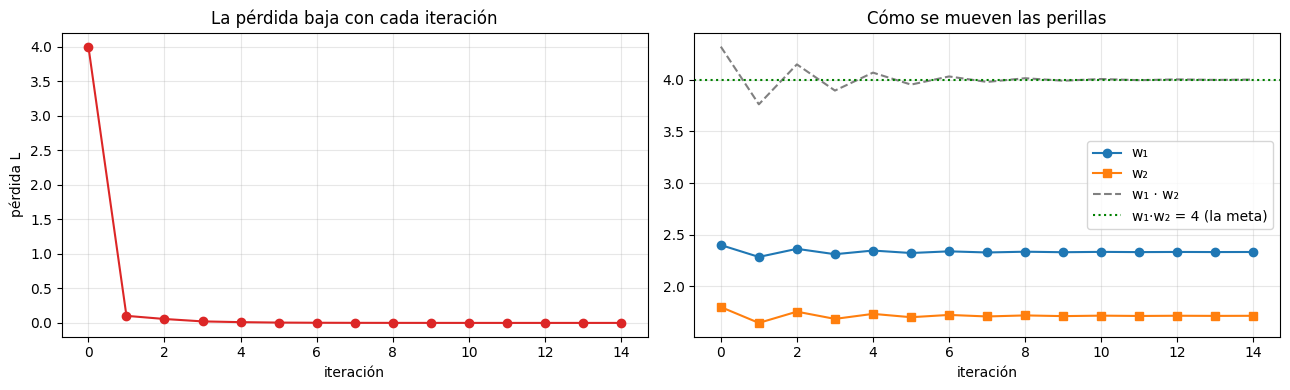

In [18]:
registro = np.array(registro)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(registro[:, 0], "o-", color=ROJO)
axes[0].set_title("La pérdida baja con cada iteración"); axes[0].set_xlabel("iteración"); axes[0].set_ylabel("pérdida L")
axes[1].plot(registro[:, 1], "o-", label="w₁")
axes[1].plot(registro[:, 2], "s-", label="w₂")
axes[1].plot(registro[:, 1] * registro[:, 2], "--", color="gray", label="w₁ · w₂")
axes[1].axhline(4, color="green", ls=":", label="w₁·w₂ = 4 (la meta)")
axes[1].set_title("Cómo se mueven las perillas"); axes[1].set_xlabel("iteración"); axes[1].legend()
plt.tight_layout(); plt.show()

Observación curiosa: la red llegó a una solución donde $w_1 \cdot w_2 \approx 4$, pero no existe una única respuesta correcta: $w_1 = 2,\, w_2 = 2$ funciona, y también $w_1 = 4,\, w_2 = 1$. Las redes reales también tienen muchísimas soluciones posibles; backpropagation solo encuentra *una* que funciona.

---

### Resumen de la Sección 6

Backpropagation = regla de la cadena aplicada de atrás hacia adelante, reutilizando cálculos.

1. Ida (forward): calcula y guarda los valores de cada sección.
2. Error: compara la salida con la respuesta correcta.
3. Vuelta (backward): empieza en el error y, sección por sección, multiplica *"la corrección que llega"* × *"la derivada local"*.
4. Ajuste: mueve cada peso un poquito en contra de su gradiente.

---
## 7. Funciones de activación: una sección más en la cadena

### ¿Por qué hacen falta?

Mira de nuevo nuestra red de la Sección 6: $y = w_2 \cdot (w_1 \cdot x)$. Eso es lo mismo que $y = (w_1 w_2)\cdot x$. ¡Dos capas que equivalen a una sola multiplicación! Si apilamos solo multiplicaciones y sumas, por más capas que pongamos, la red solo puede dibujar líneas rectas. Y el mundo (una radiografía, una voz, un dígito escrito a mano) no es una línea recta.

La solución: después de cada capa, pasar el resultado por una función de activación que "doble" la línea.

### La función sigmoide

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Piénsala como un interruptor suave (un *dimmer*): números muy negativos → casi 0 (apagado); números muy positivos → casi 1 (encendido); cerca de 0 → valores intermedios.

Su derivada local tiene una forma sencilla:

$$\sigma'(z) = \sigma(z)\,\big(1 - \sigma(z)\big)$$

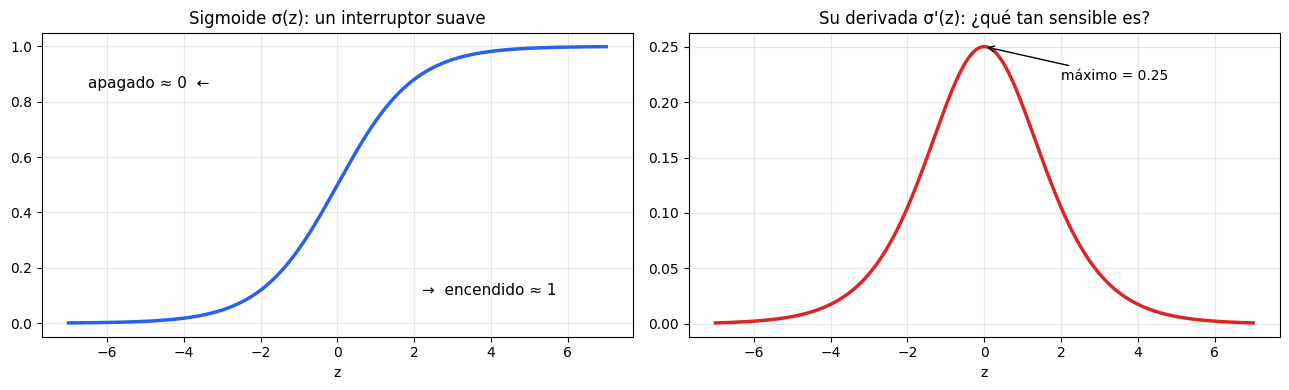

In [19]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def derivada_sigmoide(z):
    s = sigmoide(z)
    return s * (1 - s)

z = np.linspace(-7, 7, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(z, sigmoide(z), color=AZUL, lw=2.5)
axes[0].set_title("Sigmoide σ(z): un interruptor suave"); axes[0].set_xlabel("z")
axes[0].text(-6.5, 0.85, "apagado ≈ 0  ←", fontsize=11); axes[0].text(2.2, 0.1, "→  encendido ≈ 1", fontsize=11)
axes[1].plot(z, derivada_sigmoide(z), color=ROJO, lw=2.5)
axes[1].set_title("Su derivada σ'(z): ¿qué tan sensible es?"); axes[1].set_xlabel("z")
axes[1].annotate("máximo = 0.25", (0, 0.25), xytext=(2, 0.22), arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); plt.show()

Observa la derivada: es grande cerca de $z=0$ y casi cero en los extremos. Cuando una neurona está muy "apagada" o muy "encendida", es poco sensible a los cambios y deja pasar muy poca corrección hacia atrás. (A esto se le llama *desvanecimiento del gradiente*, un problema famoso de las redes profundas.)

### Ejemplo: una neurona con sigmoide

¿Aprueba o no aprueba? Un estudiante estudió $x = 2$ horas y sí aprobó ($y_{\text{real}} = 1$). La neurona:

$$z = w\cdot x + b \quad\longrightarrow\quad a = \sigma(z) \quad\longrightarrow\quad L = (a - y_{\text{real}})^2$$

Aparece un nuevo parámetro, $b$, el sesgo (*bias*): una perilla que no multiplica a nada, solo suma. Empezamos con $w = 0.5$, $b = 0$.

Es exactamente la misma receta de la Sección 6, con una sección más:

| Sección | Derivada local |
|------|----------------|
| $L = (a - y_{\text{real}})^2$ | $\dfrac{\partial L}{\partial a} = 2(a - y_{\text{real}})$ |
| $a = \sigma(z)$ | $\dfrac{\partial a}{\partial z} = a(1-a)$ |
| $z = w\cdot x + b$ | $\dfrac{\partial z}{\partial w} = x \qquad \dfrac{\partial z}{\partial b} = 1$ |

Forward:  z = 1.0000, a = σ(z) = 0.7311, L = 0.0723
Backward: ∂L/∂a = -0.5379, ∂L/∂z = -0.1058
          ∂L/∂w = -0.2115, ∂L/∂b = -0.1058

Comprobación empujando: ∂L/∂w ≈ -0.2113, ∂L/∂b ≈ -0.1057


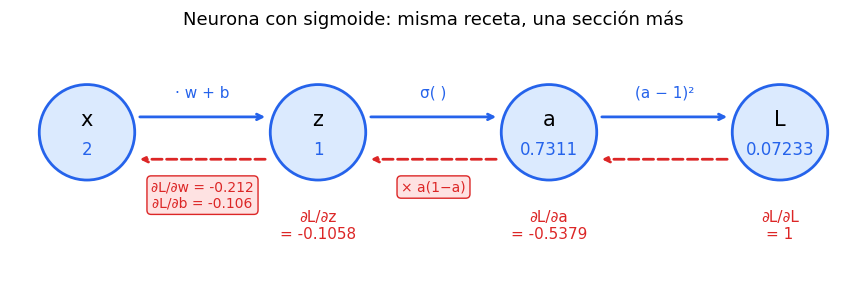

In [20]:
x, y_real = 2.0, 1.0
w, b = 0.5, 0.0

# ---- Forward ----
z = w * x + b
a = sigmoide(z)
L = (a - y_real) ** 2

# ---- Backward (corrección que llega × derivada local) ----
dL_da = 2 * (a - y_real)
dL_dz = dL_da * a * (1 - a)      # derivada local de la sigmoide: a(1-a)
dL_dw = dL_dz * x
dL_db = dL_dz * 1

print(f"Forward:  z = {z:.4f}, a = σ(z) = {a:.4f}, L = {L:.4f}")
print(f"Backward: ∂L/∂a = {dL_da:.4f}, ∂L/∂z = {dL_dz:.4f}")
print(f"          ∂L/∂w = {dL_dw:.4f}, ∂L/∂b = {dL_db:.4f}")

# Comprobación empujando:
perdida_wb = lambda w, b: (sigmoide(w * x + b) - y_real) ** 2
print(f"\nComprobación empujando: ∂L/∂w ≈ {derivada_numerica(lambda t: perdida_wb(t, b), w):.4f}, "
      f"∂L/∂b ≈ {derivada_numerica(lambda t: perdida_wb(w, t), b):.4f}")

dibujar_cadena(["x", "z", "a", "L"],
               ["· w + b", "σ( )", f"(a − {y_real:g})²"],
               [x, z, a, L],
               gradientes=[None, dL_dz, dL_da, 1.0],
               grad_ops=[f"∂L/∂w = {dL_dw:.3f}\n∂L/∂b = {dL_db:.3f}", "× a(1−a)", None],
               titulo="Neurona con sigmoide: misma receta, una sección más")

Y si repetimos el ciclo muchas veces, la neurona aprende a decir "aprobó" con cada vez más seguridad:

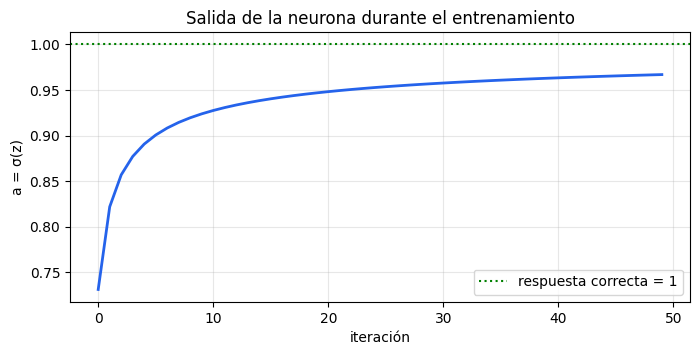

Al final: a = 0.967


In [21]:
w, b, eta = 0.5, 0.0, 1.0
salidas = []
for it in range(50):
    z = w * x + b; a = sigmoide(z)                 # forward
    dL_dz = 2 * (a - y_real) * a * (1 - a)         # backward
    w -= eta * dL_dz * x; b -= eta * dL_dz         # ajuste
    salidas.append(a)

plt.figure(figsize=(8, 3.5))
plt.plot(salidas, color=AZUL, lw=2)
plt.axhline(1, ls=":", color="green", label="respuesta correcta = 1")
plt.title("Salida de la neurona durante el entrenamiento"); plt.xlabel("iteración"); plt.ylabel("a = σ(z)")
plt.legend(); plt.show()
print(f"Al final: a = {salidas[-1]:.3f}")

---
## 8. De una neurona a una red: lo mismo, pero con muchas neuronas

Una red neuronal "de verdad" tiene capas con muchas neuronas cada una. Cada neurona de una capa recibe la salida de todas las neuronas de la capa anterior.

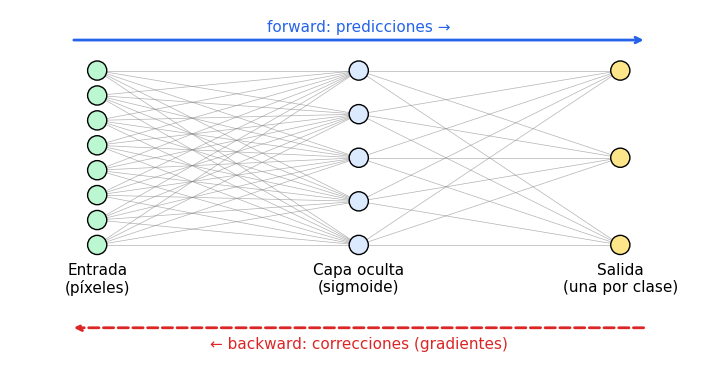

In [22]:
def dibujar_red(tamaños, nombres):
    fig, ax = plt.subplots(figsize=(9, 5))
    pos = []
    for i, n in enumerate(tamaños):
        ys = np.linspace(-1, 1, n) if n > 1 else [0]
        pos.append([(i * 3, yy) for yy in ys])
    for capa, sig in zip(pos[:-1], pos[1:]):
        for (x0, y0) in capa:
            for (x1, y1) in sig:
                ax.plot([x0, x1], [y0, y1], color="gray", lw=0.5, alpha=0.6)
    colores = ["#bbf7d0", "#dbeafe", "#fde68a"]
    for i, capa in enumerate(pos):
        for (cx, cy) in capa:
            ax.add_patch(plt.Circle((cx, cy), 0.11, color=colores[i], ec="black", zorder=3))
        ax.text(i * 3, -1.2, nombres[i], ha="center", va="top", fontsize=11)
    ax.annotate("", xy=(6.3, 1.35), xytext=(-0.3, 1.35), arrowprops=dict(arrowstyle="->", color=AZUL, lw=2))
    ax.text(3, 1.45, "forward: predicciones →", ha="center", color=AZUL, fontsize=11)
    ax.annotate("", xy=(-0.3, -1.95), xytext=(6.3, -1.95), arrowprops=dict(arrowstyle="->", color=ROJO, lw=2, ls="--"))
    ax.text(3, -2.05, "← backward: correcciones (gradientes)", ha="center", va="top", color=ROJO, fontsize=11)
    ax.set_xlim(-1, 7); ax.set_ylim(-2.4, 1.7); ax.set_aspect("equal"); ax.axis("off")
    plt.show()

dibujar_red([8, 5, 3], ["Entrada\n(píxeles)", "Capa oculta\n(sigmoide)", "Salida\n(una por clase)"])

Parece más complicado, pero es exactamente la misma receta. La única diferencia es que ahora llevamos las cuentas con vectores y matrices (tablas de números), para hacer muchas multiplicaciones a la vez.

### La señal de corrección de cada neurona: $\delta$

A la señal de corrección que recibe cada neurona (lo que antes llamamos $\partial L / \partial z$) se le suele llamar delta, $\delta$. Las reglas son tres, y todas corresponden a pasos de la Sección 6:

1. Corrección de las neuronas de salida:
$$\delta_{\text{salida}} = \text{predicción} - \text{respuesta correcta}$$
*(es como el* $2(y - y_\text{real})$ *de antes; el 2 desaparece por la función de pérdida que usaremos)*

2. Corrección de una neurona oculta:
$$\delta_{\text{oculta}} = \Big(\textstyle\sum \text{peso} \times \delta_{\text{siguiente}}\Big) \times \sigma'(z)$$
En palabras: *la corrección de una neurona oculta es la suma de las correcciones de todas las neuronas a las que alimenta, ponderadas por qué tanto les aporta (el peso), multiplicada por qué tan sensible estaba (la derivada de la sigmoide).* Es el paso (C) de la Sección 6, pero sumando varias flechas.

3. Gradiente de cada peso:
$$\frac{\partial L}{\partial w} = \delta_{\text{neurona de destino}} \times \text{valor de la neurona de origen}$$
Es el paso (B) / (D) de la Sección 6: *corrección que llega × lo que entró por ese cable*.

### Dos piezas nuevas para clasificar: softmax y entropía cruzada

Para clasificar (por ejemplo, ¿qué dígito es: 0, 1, ..., 9?), la red tiene una neurona de salida por cada clase.

- Softmax convierte los números de salida en probabilidades que suman 1. "Estoy 80 % seguro de que es un 7, 15 % de que es un 1...".
- Entropía cruzada es la pérdida para clasificar: $L = -\log(\text{probabilidad que la red le dio a la respuesta correcta})$. Si la red está segura y acierta, $L$ es pequeña; si estaba segura y se equivocó, $L$ es enorme.

In [23]:
def softmax(z):
    e = np.exp(z - z.max(axis=-1, keepdims=True))   # restar el máximo evita números gigantes
    return e / e.sum(axis=-1, keepdims=True)

puntajes = np.array([1.0, 3.0, 0.5])
print("Puntajes de la red:   ", puntajes)
print("Probabilidades softmax:", np.round(softmax(puntajes), 3), "→ suman", round(softmax(puntajes).sum(), 6))

print("\nEntropía cruzada = −log(probabilidad de la clase correcta):")
for p in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(f"  la red le dio {p:4} a la respuesta correcta → pérdida = {-np.log(p):.3f}")

Puntajes de la red:    [1.  3.  0.5]
Probabilidades softmax: [0.111 0.821 0.067] → suman 1.0

Entropía cruzada = −log(probabilidad de la clase correcta):
  la red le dio 0.99 a la respuesta correcta → pérdida = 0.010
  la red le dio  0.9 a la respuesta correcta → pérdida = 0.105
  la red le dio  0.5 a la respuesta correcta → pérdida = 0.693
  la red le dio  0.1 a la respuesta correcta → pérdida = 2.303
  la red le dio 0.01 a la respuesta correcta → pérdida = 4.605


> El regalo de combinar softmax + entropía cruzada: cuando se usan juntas, la corrección de la salida queda simplemente como $\delta = \text{probabilidades} - \text{respuesta correcta}$. Por ejemplo, si la respuesta es la clase 1 y la red dijo `[0.2, 0.7, 0.1]`, la corrección es `[0.2, -0.3, 0.1]`: *"baja un poco la clase 0, sube la clase 1, baja un poco la clase 2"*.

---
## 9. Proyecto: una red que aprende a reconocer dígitos escritos a mano

Vamos a juntar todo. Usaremos un conjunto de datos de 1797 imágenes de dígitos (del 0 al 9) escritos a mano, de $8 \times 8$ píxeles. Viene incluido en `scikit-learn`, así que no hay que descargar nada.

### 9.1 Conozcamos los datos

Número de imágenes: 1797
Tamaño de cada imagen: (8, 8) → 64 píxeles


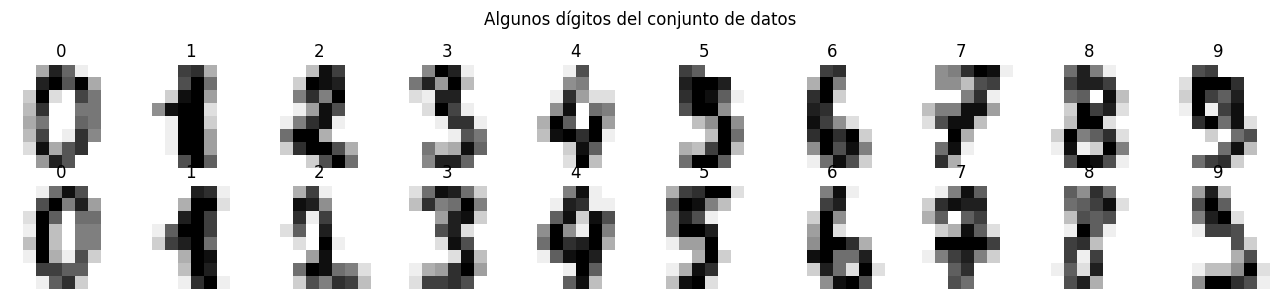

In [24]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digitos = load_digits()
imagenes, etiquetas = digitos.images, digitos.target
print("Número de imágenes:", len(imagenes))
print("Tamaño de cada imagen:", imagenes[0].shape, "→", imagenes[0].size, "píxeles")

fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for ax, img, etq in zip(axes.ravel(), imagenes, etiquetas):
    ax.imshow(img, cmap="gray_r"); ax.set_title(str(etq)); ax.axis("off")
plt.suptitle("Algunos dígitos del conjunto de datos"); plt.tight_layout(); plt.show()

Para la computadora, cada imagen es solo una lista de 64 números (la intensidad de cada píxel, de 0 a 16):

In [25]:
print("La imagen del primer dígito (un", etiquetas[0],") vista como números:\n")
print(imagenes[0].astype(int))

La imagen del primer dígito (un 0 ) vista como números:

[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


### 9.2 Preparar los datos

1. Aplanar: convertir cada imagen de $8\times8$ en una fila de 64 números.
2. Escalar: dividir entre 16 para que los números queden entre 0 y 1 (a las redes les gustan los números pequeños).
3. Separar: 80 % para entrenar y 20 % para evaluar con imágenes que la red nunca vio (como un examen con preguntas nuevas).
4. One-hot: convertir cada etiqueta en un vector. El dígito 3 se vuelve `[0,0,0,1,0,0,0,0,0,0]`.

In [26]:
X = imagenes.reshape(len(imagenes), -1) / 16.0          # (1797, 64), valores entre 0 y 1

X_entreno, X_prueba, y_entreno, y_prueba = train_test_split(
    X, etiquetas, test_size=0.2, random_state=0, stratify=etiquetas)

def one_hot(y, n_clases=10):
    return np.eye(n_clases)[y]

Y_entreno = one_hot(y_entreno)
Y_prueba = one_hot(y_prueba)

print("Entrenamiento:", X_entreno.shape, " Prueba:", X_prueba.shape)
print(f"Etiqueta {y_entreno[0]} en one-hot → {Y_entreno[0].astype(int)}")

Entrenamiento: (1437, 64)  Prueba: (360, 64)
Etiqueta 3 en one-hot → [0 0 0 1 0 0 0 0 0 0]


### 9.3 La red neuronal, hecha a mano con NumPy

Arquitectura: 64 entradas → 32 neuronas ocultas (sigmoide) → 10 salidas (softmax).

Lee los comentarios del método `backward`: cada línea corresponde a un paso que ya hiciste a mano en la Sección 6.

Nota sobre las matrices: procesamos varias imágenes a la vez (un *lote* o *batch*). Cada fila de `X` es una imagen. La operación `X @ W1` hace todas las multiplicaciones "peso × entrada" de todas las neuronas y todas las imágenes de un solo golpe. No es una idea nueva, solo una forma eficiente de llevar las cuentas.

In [27]:
class RedNeuronal:
    def __init__(self, n_entrada, n_oculta, n_salida):
        # Pesos iniciales: números aleatorios pequeños. Sesgos: ceros.
        self.W1 = np.random.randn(n_entrada, n_oculta) / np.sqrt(n_entrada)
        self.b1 = np.zeros(n_oculta)
        self.W2 = np.random.randn(n_oculta, n_salida) / np.sqrt(n_oculta)
        self.b2 = np.zeros(n_salida)

    def forward(self, X):
        """IDA: calcula la predicción y GUARDA los valores intermedios (los necesitaremos de vuelta)."""
        self.X  = X
        self.Z1 = X @ self.W1 + self.b1        # capa oculta: suma ponderada  (z = w·x + b)
        self.A1 = sigmoide(self.Z1)            # capa oculta: activación      (a = σ(z))
        self.Z2 = self.A1 @ self.W2 + self.b2  # capa de salida: suma ponderada
        self.P  = softmax(self.Z2)             # capa de salida: probabilidades
        return self.P

    def perdida(self, Y):
        """Entropía cruzada promedio: −log(probabilidad de la respuesta correcta)."""
        return -np.mean(np.sum(Y * np.log(self.P + 1e-12), axis=1))

    def backward(self, Y):
        """VUELTA: enmienda el error desde la salida hasta la entrada."""
        n = len(Y)
        # (A) Corrección de la salida (regalo de softmax + entropía cruzada): predicción − correcto
        delta2 = (self.P - Y) / n
        # (B) Gradiente de los pesos de salida: corrección que llega × lo que entró por el cable (A1)
        self.dW2 = self.A1.T @ delta2
        self.db2 = delta2.sum(axis=0)
        # (C) Corrección que pasa a la capa oculta: suma(peso × corrección siguiente) × derivada de la sigmoide
        delta1 = (delta2 @ self.W2.T) * self.A1 * (1 - self.A1)
        # (D) Gradiente de los pesos ocultos: corrección que llega × lo que entró por el cable (X)
        self.dW1 = self.X.T @ delta1
        self.db1 = delta1.sum(axis=0)

    def actualizar(self, eta):
        """AJUSTE: descenso del gradiente, girar cada perilla en contra de su gradiente."""
        self.W1 -= eta * self.dW1;  self.b1 -= eta * self.db1
        self.W2 -= eta * self.dW2;  self.b2 -= eta * self.db2

    def predecir(self, X):
        return np.argmax(self.forward(X), axis=1)     # la clase con mayor probabilidad

    def precision(self, X, y):
        return np.mean(self.predecir(X) == y)         # % de aciertos

red = RedNeuronal(64, 32, 10)
n_pesos = red.W1.size + red.b1.size + red.W2.size + red.b2.size
print(f"La red tiene {n_pesos} perillas (pesos + sesgos) para ajustar.")

La red tiene 2410 perillas (pesos + sesgos) para ajustar.


### 9.4 ¿Nuestro backpropagation está bien? Comprobación "empujando"

Antes de entrenar, hacemos lo mismo que en la Sección 6: elegimos algunos pesos al azar, los empujamos un poquito y comparamos con lo que dice nuestro `backward`. Esto se llama gradient checking y es lo que hacen los investigadores para encontrar errores en su código.

In [28]:
Xp, Yp = X_entreno[:20], Y_entreno[:20]     # un lote pequeño
red.forward(Xp); red.backward(Yp)

print("peso          | backprop     | empujando")
print("--------------+--------------+-------------")
for (matriz, grad, nombre) in [(red.W1, red.dW1, "W1"), (red.W2, red.dW2, "W2")]:
    for _ in range(3):
        i, j = np.random.randint(matriz.shape[0]), np.random.randint(matriz.shape[1])
        original = matriz[i, j]; h = 1e-5
        matriz[i, j] = original + h; red.forward(Xp); L_mas = red.perdida(Yp)
        matriz[i, j] = original - h; red.forward(Xp); L_menos = red.perdida(Yp)
        matriz[i, j] = original
        numerica = (L_mas - L_menos) / (2 * h)
        print(f"{nombre}[{i:2},{j:2}]     | {grad[i, j]: .8f}  | {numerica: .8f}")

peso          | backprop     | empujando
--------------+--------------+-------------
W1[18,21]     |  0.00394121  |  0.00394121
W1[ 4,26]     | -0.00766729  | -0.00766729
W1[ 1,29]     | -0.00016861  | -0.00016861
W2[14, 6]     |  0.02378665  |  0.02378665
W2[ 3, 0]     |  0.02701900  |  0.02701900
W2[12, 3]     | -0.05775019  | -0.05775019


Coinciden hasta muchos decimales. Nuestro backpropagation funciona.

### 9.5 Antes de entrenar: la red adivina al azar

Precisión SIN entrenar: 10.0%  (adivinar al azar daría ~10%)


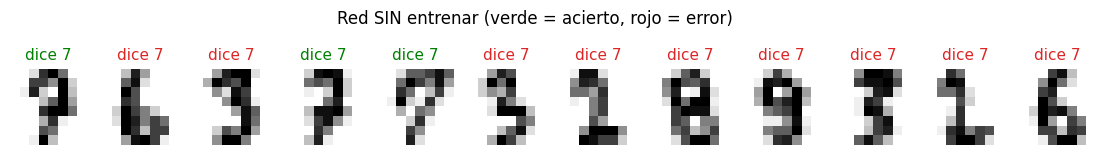

In [29]:
def mostrar_predicciones(red, titulo, n=12):
    pred = red.predecir(X_prueba[:n])
    fig, axes = plt.subplots(1, n, figsize=(14, 2))
    for ax, img, p, real in zip(axes, X_prueba[:n], pred, y_prueba[:n]):
        ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.axis("off")
        ax.set_title(f"dice {p}", color="green" if p == real else ROJO, fontsize=11)
    plt.suptitle(titulo); plt.show()

print(f"Precisión SIN entrenar: {red.precision(X_prueba, y_prueba):.1%}  (adivinar al azar daría ~10%)")
mostrar_predicciones(red, "Red SIN entrenar (verde = acierto, rojo = error)")

### 9.6 Entrenamiento

El ciclo de siempre, repetido muchas veces:

```
para cada época (una pasada por todos los datos):
    para cada lote de 32 imágenes:
        1. forward → predecir
        2. backward → enmendar el error hacia atrás
        3. actualizar → girar las perillas
```

In [30]:
red = RedNeuronal(64, 32, 10)
eta, tamaño_lote, epocas = 0.5, 32, 40
historial = {"perdida": [], "prec_entreno": [], "prec_prueba": []}

for epoca in range(epocas):
    orden = np.random.permutation(len(X_entreno))           # barajar los datos en cada época
    for k in range(0, len(orden), tamaño_lote):
        lote = orden[k:k + tamaño_lote]
        red.forward(X_entreno[lote])                        # 1. ida
        red.backward(Y_entreno[lote])                       # 2. vuelta
        red.actualizar(eta)                                 # 3. ajuste

    red.forward(X_entreno)
    historial["perdida"].append(red.perdida(Y_entreno))
    historial["prec_entreno"].append(red.precision(X_entreno, y_entreno))
    historial["prec_prueba"].append(red.precision(X_prueba, y_prueba))
    if epoca % 5 == 0 or epoca == epocas - 1:
        print(f"Época {epoca+1:2}: pérdida = {historial['perdida'][-1]:.4f} | "
              f"precisión en prueba = {historial['prec_prueba'][-1]:.1%}")

Época  1: pérdida = 1.8156 | precisión en prueba = 52.8%
Época  6: pérdida = 0.3317 | precisión en prueba = 93.6%
Época 11: pérdida = 0.1828 | precisión en prueba = 95.6%
Época 16: pérdida = 0.1338 | precisión en prueba = 95.6%
Época 21: pérdida = 0.1048 | precisión en prueba = 96.4%
Época 26: pérdida = 0.0883 | precisión en prueba = 96.4%
Época 31: pérdida = 0.0745 | precisión en prueba = 96.7%
Época 36: pérdida = 0.0654 | precisión en prueba = 97.2%
Época 40: pérdida = 0.0590 | precisión en prueba = 96.9%


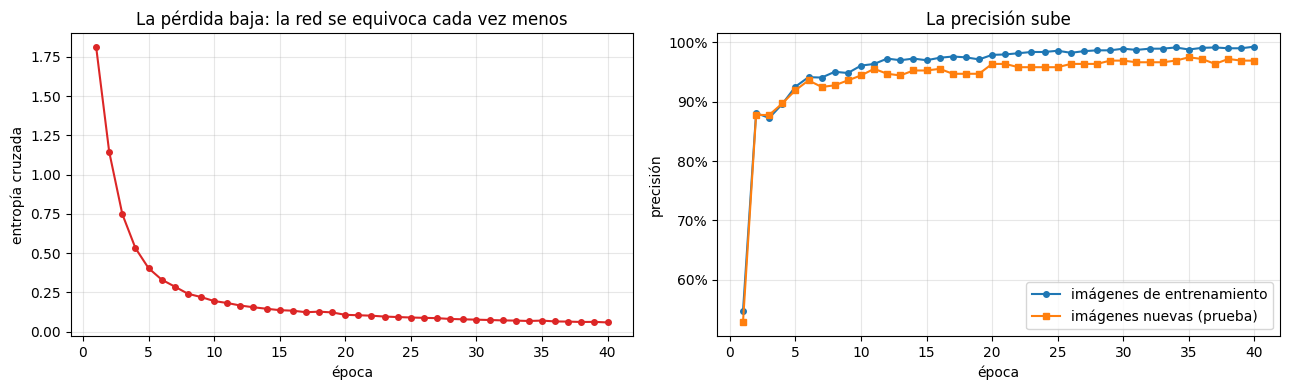

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, epocas + 1), historial["perdida"], "o-", color=ROJO, ms=4)
axes[0].set_title("La pérdida baja: la red se equivoca cada vez menos")
axes[0].set_xlabel("época"); axes[0].set_ylabel("entropía cruzada")
axes[1].plot(range(1, epocas + 1), historial["prec_entreno"], "o-", ms=4, label="imágenes de entrenamiento")
axes[1].plot(range(1, epocas + 1), historial["prec_prueba"], "s-", ms=4, label="imágenes nuevas (prueba)")
axes[1].set_title("La precisión sube"); axes[1].set_xlabel("época"); axes[1].set_ylabel("precisión")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].legend()
plt.tight_layout(); plt.show()

Precisión DESPUÉS de entrenar: 96.9% en imágenes que nunca vio


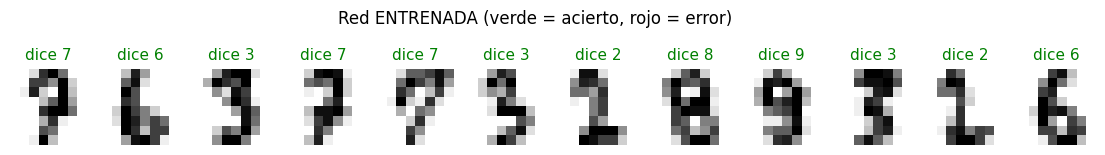

In [32]:
print(f"Precisión DESPUÉS de entrenar: {red.precision(X_prueba, y_prueba):.1%} en imágenes que nunca vio")
mostrar_predicciones(red, "Red ENTRENADA (verde = acierto, rojo = error)")

### 9.7 ¿En qué se equivoca todavía?

Mirar los errores es una de las cosas más útiles que puedes hacer con un modelo. Muchas veces son dígitos que hasta a un humano le costaría leer.

Se equivocó en 11 de 360 imágenes.


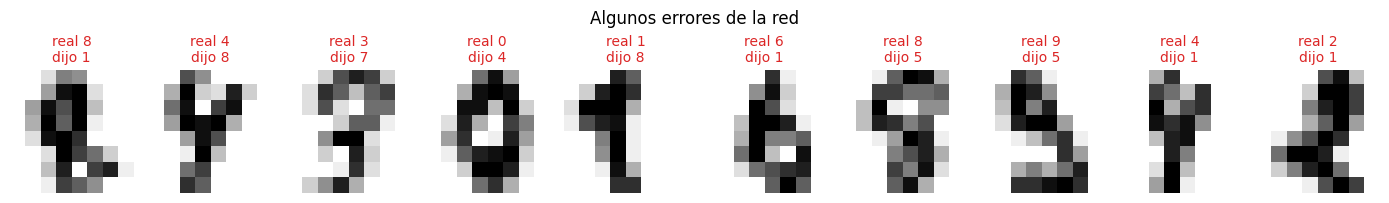

In [33]:
pred = red.predecir(X_prueba)
errores = np.where(pred != y_prueba)[0]
print(f"Se equivocó en {len(errores)} de {len(y_prueba)} imágenes.")

n = min(10, len(errores))
if n > 0:
    fig, axes = plt.subplots(1, n, figsize=(1.4 * n, 2.2))
    for ax, i in zip(np.atleast_1d(axes), errores[:n]):
        ax.imshow(X_prueba[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
        ax.set_title(f"real {y_prueba[i]}\ndijo {pred[i]}", color=ROJO, fontsize=10)
    plt.suptitle("Algunos errores de la red"); plt.tight_layout(); plt.show()

### 9.8 ¿Qué "mira" cada neurona oculta?

Cada una de las 32 neuronas ocultas tiene 64 pesos, uno por píxel. Si los acomodamos como una imagen de $8\times8$, vemos qué patrón activa a esa neurona: azul = píxeles que la "encienden", rojo = píxeles que la "apagan". Nadie le dijo a la red qué patrones buscar: los descubrió sola gracias a backpropagation.

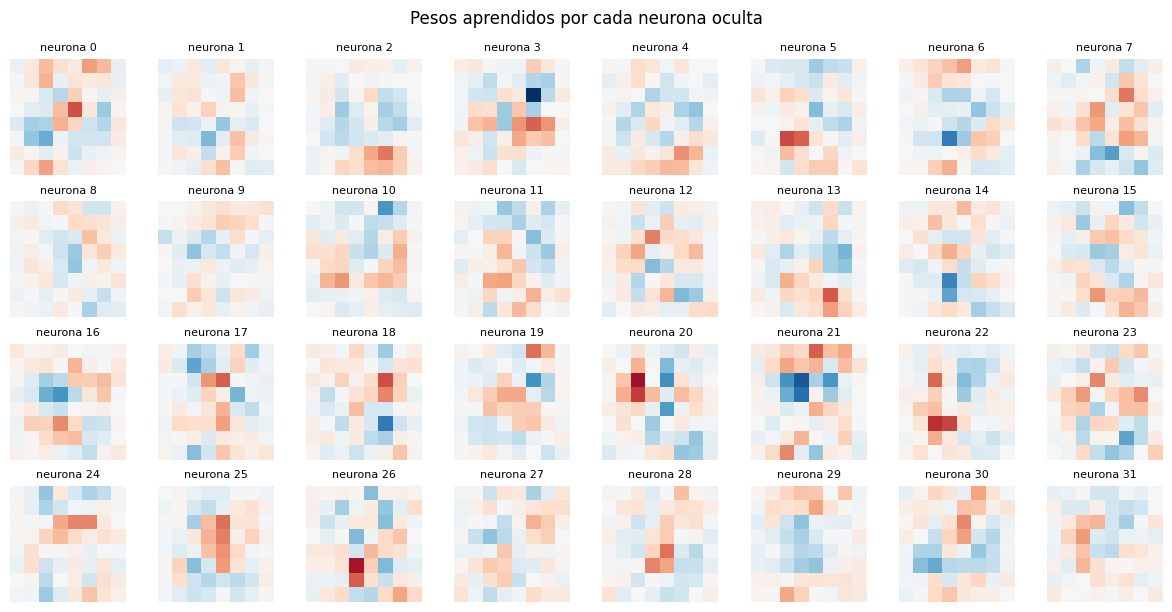

In [34]:
fig, axes = plt.subplots(4, 8, figsize=(12, 6.2))
lim = np.abs(red.W1).max()
for k, ax in enumerate(axes.ravel()):
    ax.imshow(red.W1[:, k].reshape(8, 8), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_title(f"neurona {k}", fontsize=8); ax.axis("off")
plt.suptitle("Pesos aprendidos por cada neurona oculta"); plt.tight_layout(); plt.show()

---
## 10. Resumen, glosario y ejercicios

### Todo el tutorial en 5 líneas

1. Una red neuronal es una función con muchas perillas (pesos).
2. La pérdida mide qué tan mal predice la red.
3. La derivada dice cuánto cambia la pérdida si movemos una perilla un poquito, y hacia qué lado.
4. Backpropagation calcula esas derivadas para *todas* las perillas, yendo del error hacia la entrada y multiplicando derivadas locales (regla de la cadena), reutilizando cálculos.
5. El descenso del gradiente mueve cada perilla un poquito en contra de su derivada. Se repite miles de veces.

### Glosario

| Término | En palabras sencillas |
|---------|----------------------|
| Peso ($w$) | Una perilla que la red puede ajustar |
| Sesgo ($b$) | Una perilla que suma en vez de multiplicar |
| Forward pass | Calcular la predicción, de la entrada a la salida |
| Pérdida / loss ($L$) | Número que mide qué tan mal predijo la red |
| Derivada / gradiente | Sensibilidad: cuánto cambia $L$ si muevo una perilla |
| Regla de la cadena | Las sensibilidades de una cadena se multiplican |
| Backpropagation | Calcular todos los gradientes yendo hacia atrás |
| Tasa de aprendizaje ($\eta$) | El tamaño de cada paso al ajustar |
| Función de activación | Sección que "dobla" la línea (p. ej. sigmoide) |
| Época | Una pasada completa por todos los datos de entrenamiento |
| Lote / batch | Grupo de ejemplos que se procesan juntos |

### ¿Y en la vida real?

Librerías como PyTorch o TensorFlow hacen backpropagation automáticamente. Cuando en PyTorch escribes `perdida.backward()`, por dentro ocurre exactamente lo que hiciste a mano en la Sección 6: cada operación guarda su derivada local, y al final se multiplican de atrás hacia adelante.

---

### Ejercicios

Ejercicio 1 (lápiz y papel, luego verifica con código). Usa la red de la Sección 6 con $x = 2$, $w_1 = 1$, $w_2 = 3$, $y_{\text{real}} = 10$. Calcula a mano $h$, $y$, $L$, $\dfrac{\partial L}{\partial y}$, $\dfrac{\partial L}{\partial w_2}$, $\dfrac{\partial L}{\partial h}$ y $\dfrac{\partial L}{\partial w_1}$. ¿Hacia dónde hay que mover cada peso?

<details>
<summary> Ver solución</summary>

- $h = 1 \cdot 2 = 2$, $\;y = 3 \cdot 2 = 6$, $\;L = (6-10)^2 = 16$
- $\partial L/\partial y = 2(6 - 10) = -8$
- $\partial L/\partial w_2 = -8 \cdot h = -16$
- $\partial L/\partial h = -8 \cdot w_2 = -24$
- $\partial L/\partial w_1 = -24 \cdot x = -48$

Ambos gradientes son negativos → hay que subir los dos pesos ($w_1$ bastante más que $w_2$).
</details>

In [35]:
# Ejercicio 1: escribe tus respuestas aquí y ejecuta la celda para comprobarlas
mis_respuestas = {
    "h": None, "y": None, "L": None,
    "dL_dy": None, "dL_dw2": None, "dL_dh": None, "dL_dw1": None,
}

# --- No modifiques lo de abajo ---
x_, w1_, w2_, yr_ = 2, 1, 3, 10
h_ = w1_ * x_; y_ = w2_ * h_; L_ = (y_ - yr_) ** 2
dy_ = 2 * (y_ - yr_)
correctas = {"h": h_, "y": y_, "L": L_, "dL_dy": dy_, "dL_dw2": dy_ * h_,
             "dL_dh": dy_ * w2_, "dL_dw1": dy_ * w2_ * x_}
for k, v in correctas.items():
    r = mis_respuestas[k]
    estado = "sin responder" if r is None else ("correcto" if np.isclose(r, v) else "revisa")
    print(f"{k:7}: {estado}")

h      : sin responder
y      : sin responder
L      : sin responder
dL_dy  : sin responder
dL_dw2 : sin responder
dL_dh  : sin responder
dL_dw1 : sin responder


Ejercicio 2 (tasa de aprendizaje). En la Sección 9.6 cambia `eta` a `0.05`, luego a `0.5` y luego a `10`. ¿Qué pasa con la curva de pérdida en cada caso? Relaciónalo con el experimento de la Sección 3.

Ejercicio 3 (tamaño de la red). Cambia el número de neuronas ocultas de `32` a `4` y luego a `128`. ¿Cambia la precisión? ¿Y el tiempo que tarda?

Ejercicio 4 (pregunta conceptual). Con tus palabras: ¿por qué decimos que backpropagation es *eficiente*? ¿Qué cálculo se "reutiliza"?

<details>
<summary> Pista para el ejercicio 4</summary>

En la Sección 6, $\partial L/\partial y$ se usó para calcular tanto $\partial L/\partial w_2$ como $\partial L/\partial h$, y $\partial L/\partial h$ se usó para calcular $\partial L/\partial w_1$. Cada capa recibe la corrección ya calculada por la capa siguiente, en vez de recalcular todo el camino hasta el error. Con "empujar" pesos habría que ejecutar la red completa una vez por cada peso.
</details>

Ejercicio 5 (reto ). Agrega una tercera estación a la red de la Sección 6: $x \to h_1 = w_1 x \to h_2 = w_2 h_1 \to y = w_3 h_2 \to L$. Escribe el forward y el backward en código y compruébalo "empujando" cada peso.